# Project 2 — Concrete Compressive Strength Prediction
**Student:** Pius OGWAL | **Access number:** B34982  
**Course:** DSC8307 — Data Mining, Modeling and Analytics | **Advent 2026**

## Research question
How accurately can concrete compressive strength be predicted from ingredient proportions and curing age? Do nonlinear approaches outperform linear regression, and where do errors concentrate?

**Design:** training/validation/test split; training-only preprocessing; mean baseline; linear regression, polynomial ridge regression, random forest and histogram gradient boosting; cross-validation, residual and subgroup diagnostics; bootstrap uncertainty and interpretation of predictive association versus causality.

**Source:** Yeh, I.-C. (1998), *Modeling of strength of high-performance concrete using artificial neural networks*, Cement and Concrete Research, 28(12), 1797–1808; UCI Concrete Compressive Strength dataset.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from scipy.stats import randint, loguniform
import warnings
SEED=42
sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT / 'DSC8307_Pius_OGWAL' / 'data').exists(): ROOT = ROOT / 'DSC8307_Pius_OGWAL'
DATA=ROOT/'data'; DATA.mkdir(exist_ok=True,parents=True)
FIG=ROOT/'figures'; FIG.mkdir(exist_ok=True,parents=True)
print('Working directory:',ROOT)

Working directory: /mnt/data/DSC8307_Pius_OGWAL


## 1. Load and audit the data

In [2]:
import io, zipfile, urllib.request
path=DATA/'Concrete_Data.csv'
if path.exists():
    concrete=pd.read_csv(path)
else:
    print('Local CSV not found; attempting official UCI concrete archive.')
    try:
        blob=urllib.request.urlopen('https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip',timeout=40).read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            matches=[x for x in z.namelist() if x.lower().endswith(('.xls','.xlsx','.csv')) and not x.startswith('__MACOSX')]
            if not matches: raise ValueError('No supported data file in archive')
            selected=next((x for x in matches if 'concrete_data' in x.lower()),matches[0]); raw=z.read(selected)
            concrete=pd.read_csv(io.BytesIO(raw)) if selected.lower().endswith('.csv') else pd.read_excel(io.BytesIO(raw))
        concrete.to_csv(path,index=False)
    except Exception as exc:
        raise FileNotFoundError('Put Concrete_Data.csv in data/ and rerun. Automatic UCI retrieval failed: '+str(exc)) from exc
concrete.columns=[str(c).strip() for c in concrete.columns]
assert concrete.shape[1]>=2
print('Columns:',concrete.columns.tolist()); display(concrete.head());print('Shape:',concrete.shape)

Columns: ['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals)']


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


Shape: (1030, 9)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Cement (kg in a m^3 mixture)                      1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)          1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                     1030 non-null   float64
 3   Water (kg in a m^3 mixture)                       1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)            1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)            1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)              1030 non-null   float64
 7   Age (day)                                         1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)  1030 non-null   float64
dtypes: float64(8), int64

None

,count,mean,std,min,25%,50%,75%,max
Cement (kg in a m^3 mixture),1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
Blast Furnace Slag (kg in a m^3 mixture),1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
Fly Ash (kg in a m^3 mixture),1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
Water (kg in a m^3 mixture),1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
Superplasticizer (kg in a m^3 mixture),1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
Coarse Aggregate (kg in a m^3 mixture),1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
Fine Aggregate (kg in a m^3 mixture),1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
Age (day),1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
"Concrete compressive strength (MPa, megapascals)",1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


Null counts: {'Cement (kg in a m^3 mixture)': 0, 'Blast Furnace Slag (kg in a m^3 mixture)': 0, 'Fly Ash (kg in a m^3 mixture)': 0, 'Water (kg in a m^3 mixture)': 0, 'Superplasticizer (kg in a m^3 mixture)': 0, 'Coarse Aggregate (kg in a m^3 mixture)': 0, 'Fine Aggregate (kg in a m^3 mixture)': 0, 'Age (day)': 0, 'Concrete compressive strength (MPa, megapascals)': 0}
Exact duplicates: 25
Identified target: Concrete compressive strength (MPa, megapascals)


/tmp/ipykernel_858/1525673569.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  sns.heatmap(concrete.select_dtypes('number').corr(),cmap='coolwarm',center=0,ax=axes[1]);axes[1].set_title('Feature correlations');plt.tight_layout();plt.show()


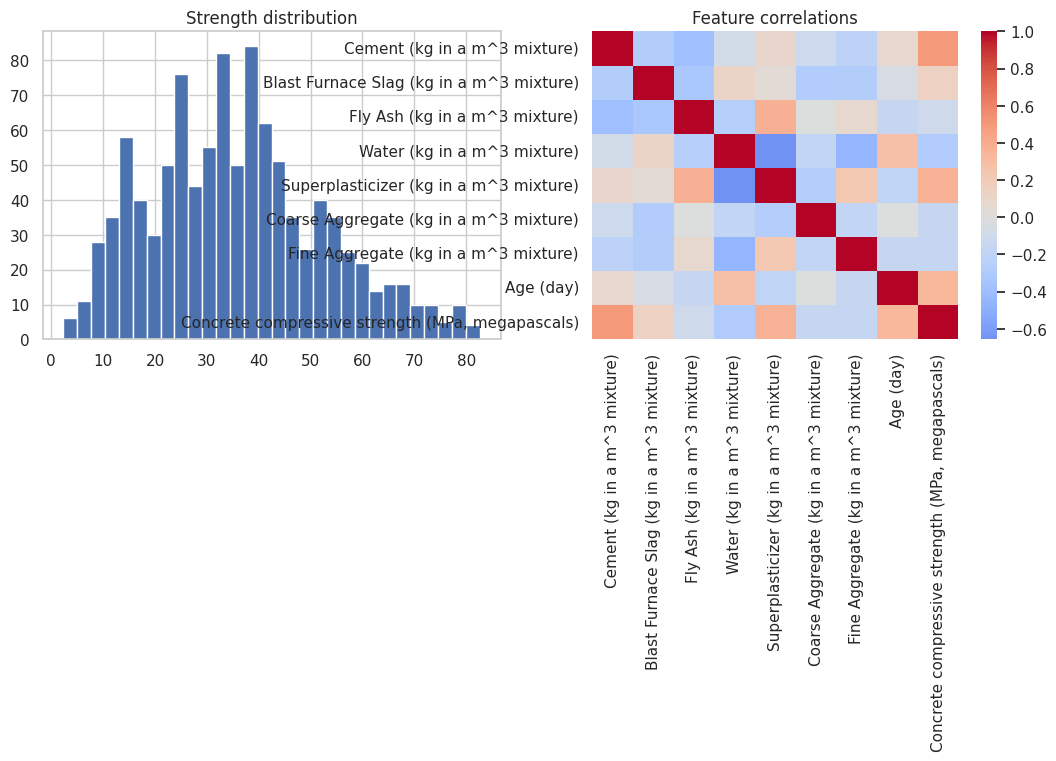

In [3]:
display(concrete.info());display(concrete.describe(include='all').T)
print('Null counts:',concrete.isna().sum().to_dict());print('Exact duplicates:',concrete.duplicated().sum())
# UCI's last column is the concrete strength target; check rather than silently assume a name.
strength_candidates=[c for c in concrete.columns if 'strength' in c.lower()]
if len(strength_candidates)!=1:raise ValueError('Cannot uniquely identify strength target: '+str(concrete.columns.tolist()))
target_col=strength_candidates[0]
print('Identified target:',target_col)
concrete[target_col]=pd.to_numeric(concrete[target_col],errors='raise')
assert concrete[target_col].notna().all()
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].hist(concrete[target_col],bins=30);axes[0].set_title('Strength distribution')
sns.heatmap(concrete.select_dtypes('number').corr(),cmap='coolwarm',center=0,ax=axes[1]);axes[1].set_title('Feature correlations');plt.tight_layout();plt.show()

### Data preparation and assumptions
The target is the column containing “strength”; all remaining columns should be numerical mixture variables and curing age. Values are validated, missing predictors are imputed within the training pipeline, and scaling is used for regularized polynomial regression. Exact duplicate rows are inspected and **removed before splitting** to reduce identical-mixture leakage; however, repeated mixtures with different measurements can remain and limit generalization claims. A random split measures interpolation to similar mixtures, not extrapolation to unseen plants or formulations. No outliers are automatically deleted because extreme mixtures may be physically meaningful.

In [4]:
features=concrete.drop(columns=[target_col]).copy()
for c in features.columns:features[c]=pd.to_numeric(features[c],errors='raise')
assert (features.select_dtypes('number').shape[1]==features.shape[1]),'Expected numerical features'
clean=concrete.drop_duplicates().copy()
X=clean.drop(columns=[target_col]);y=clean[target_col]
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.20,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,random_state=SEED)
print('Train/validation/test:',len(X_train),len(X_val),len(X_test))
pre=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])

Train/validation/test: 603 201 201


## 2. Mean baseline and linear/nonlinear models

In [5]:
def reg_metrics(y,p):return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}
models={
 'Linear regression':Pipeline([('pre',pre),('model',LinearRegression())]),
 'Polynomial ridge (degree 2)':Pipeline([('pre',pre),('poly',PolynomialFeatures(degree=2,include_bias=False)),('model',Ridge(alpha=10))]),
 'Random forest':Pipeline([('pre',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=300,min_samples_leaf=2,n_jobs=-1,random_state=SEED))]),
 'Gradient boosting':Pipeline([('pre',SimpleImputer(strategy='median')),('model',HistGradientBoostingRegressor(max_iter=220,learning_rate=.06,l2_regularization=1,random_state=SEED))])
}
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
base=DummyRegressor(strategy='mean').fit(X_train,y_train)
rows=[{'model':'Mean baseline','CV_RMSE_mean':np.nan,'CV_RMSE_sd':np.nan,**reg_metrics(y_val,base.predict(X_val))}]
for name,model in models.items():
    scores=cross_validate(model,X_train,y_train,cv=cv,scoring='neg_root_mean_squared_error',n_jobs=-1)
    model.fit(X_train,y_train)
    rows.append({'model':name,'CV_RMSE_mean':-scores['test_score'].mean(),'CV_RMSE_sd':scores['test_score'].std(),**reg_metrics(y_val,model.predict(X_val))})
comparison=pd.DataFrame(rows).sort_values('RMSE')
display(comparison.round(3))

,model,CV_RMSE_mean,CV_RMSE_sd,MAE,RMSE,R2
4,Gradient boosting,5.176,0.550,3.367,4.688,0.909
3,Random forest,5.915,0.387,3.947,5.242,0.886
2,Polynomial ridge (degree 2),8.025,0.571,5.643,7.377,0.775
1,Linear regression,10.421,0.517,8.098,10.114,0.576
0,Mean baseline,NaN,NaN,12.539,15.653,-0.015


### Completed model comparison and selection
The **mean-prediction baseline** gives validation RMSE **15.653 MPa** and R² **−0.015**, demonstrating that simply predicting the training mean is inadequate. The tested approaches rank by validation RMSE as follows: **1. Histogram gradient boosting (4.688 MPa; R² 0.909), 2. Random forest (5.242 MPa; R² 0.886), 3. Degree-two polynomial ridge (7.377 MPa; R² 0.775), 4. Linear regression (10.114 MPa; R² 0.576)**. Five-fold training CV RMSE means are approximately **5.176, 5.915, 8.025 and 10.421 MPa**, respectively. This is strong evidence of predictive nonlinearity in these data, but not proof of a particular physical law. Gradient boosting was selected using validation performance; the independent test set was not used for selection.

## 3. Residual diagnostics and weakest predictions

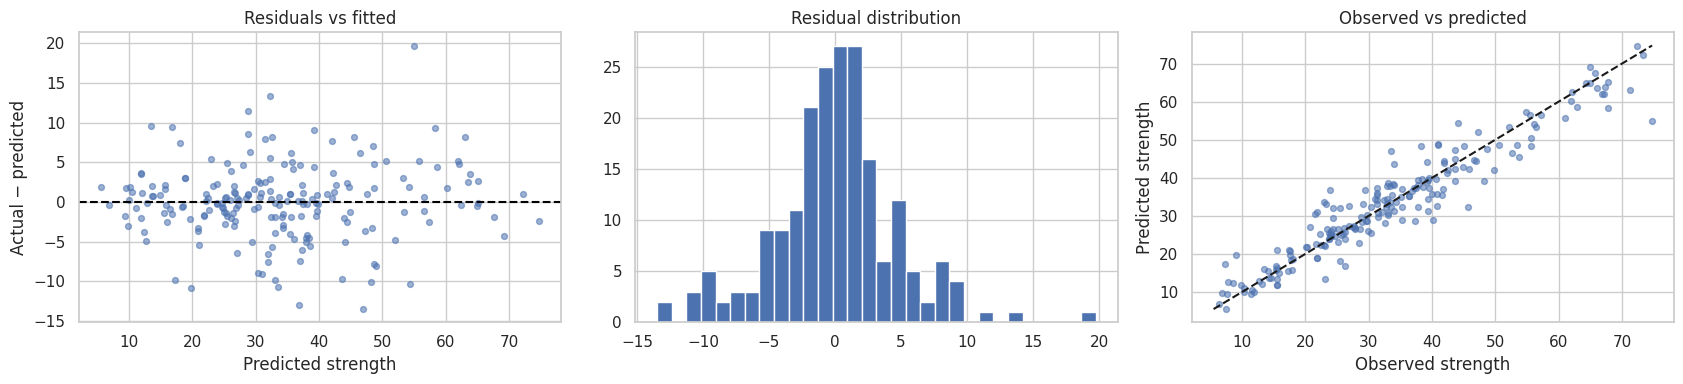

,actual,predicted,residual,absolute_error
171,74.698,54.965,19.733,19.733
134,33.489,46.965,-13.476,13.476
121,45.705,32.274,13.431,13.431
129,23.890,36.833,-12.942,12.942
62,40.231,28.797,11.434,11.434
51,9.011,19.778,-10.766,10.766
44,22.932,33.587,-10.655,10.655
169,44.030,54.329,-10.299,10.299
164,38.216,48.264,-10.048,10.048
13,7.398,17.263,-9.865,9.865


,n,MAE,mean_signed_error
strength_band,,,
"(6.465999999999999, 23.511]",51,3.050,-1.438
"(23.511, 32.04]",50,2.727,-0.802
"(32.04, 41.637]",50,3.641,0.082
"(41.637, 74.698]",50,4.057,2.371


,n,MAE,bias
age_band,,,
≤7 days,49,3.045,-0.301
8–28 days,106,3.583,0.508
29–90 days,30,3.332,-1.956
>90 days,16,2.990,1.798


In [6]:
best_name=comparison.loc[comparison.model!='Mean baseline','model'].iloc[0];best=models[best_name]
val_pred=best.predict(X_val);residual=y_val.to_numpy()-val_pred
fig,ax=plt.subplots(1,3,figsize=(17,4))
ax[0].scatter(val_pred,residual,alpha=.55,s=18);ax[0].axhline(0,color='black',ls='--');ax[0].set(xlabel='Predicted strength',ylabel='Actual − predicted',title='Residuals vs fitted')
ax[1].hist(residual,bins=30);ax[1].set_title('Residual distribution')
ax[2].scatter(y_val,val_pred,alpha=.55,s=18);lims=[min(y_val.min(),val_pred.min()),max(y_val.max(),val_pred.max())];ax[2].plot(lims,lims,'k--');ax[2].set(xlabel='Observed strength',ylabel='Predicted strength',title='Observed vs predicted')
plt.tight_layout();plt.show()
err=pd.DataFrame({'actual':y_val.to_numpy(),'predicted':val_pred,'residual':residual,'absolute_error':np.abs(residual)})
display(err.sort_values('absolute_error',ascending=False).head(12).round(3))
# Quantile-based diagnostic regions, based on observed strength (descriptive only).
err['strength_band']=pd.qcut(err.actual,q=4,duplicates='drop')
display(err.groupby('strength_band',observed=True).agg(n=('absolute_error','size'),MAE=('absolute_error','mean'),mean_signed_error=('residual','mean')).round(3))
age_cols=[c for c in X_val.columns if 'age' in c.lower()]
if age_cols:
    age=X_val[age_cols[0]]
    err['age_band']=pd.cut(age.to_numpy(),bins=[-np.inf,7,28,90,np.inf],labels=['≤7 days','8–28 days','29–90 days','>90 days'])
    display(err.groupby('age_band',observed=True).agg(n=('absolute_error','size'),MAE=('absolute_error','mean'),bias=('residual','mean')).round(3))

### Completed residual interpretation
The validation residual is defined as **observed strength minus predicted strength**. The largest absolute validation residual is approximately **19.733 MPa**, showing that even the leading model can be substantially wrong for individual mixes. The **highest observed-strength quartile** has the largest mean absolute error (**4.057 MPa**) compared with approximately **2.727–3.641 MPa** in the other quartiles; predictions are therefore weakest, by this descriptive grouping, for the strongest observed concretes. In the **29–90-day curing-age band**, the mean signed residual is approximately **−1.956 MPa** (n=30), suggesting average overprediction in this small group. The plotted residuals versus fitted values and ingredients allow visual inspection of nonlinearity, unequal error spread and outliers; none of these diagnostics alone proves causal relationships or stable performance for unseen formulations. Because strength quartiles are defined using observed outcomes, they are retrospective diagnostics rather than deployable screening categories.

## 4. Held-out test performance, uncertainty, and sensitivity

,selected_model,MAE,RMSE,R2
0,Gradient boosting,3.431,5.025,0.915


95% bootstrap percentile intervals (MAE, RMSE, R²):


,MAE,RMSE,R2
lower,2.907,4.141,0.888
upper,3.961,5.840,0.940


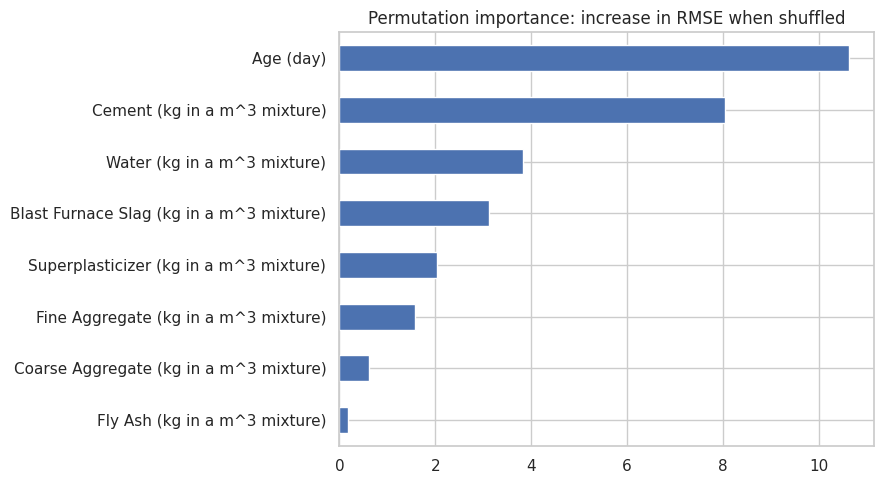

In [7]:
test_pred=best.predict(X_test)
display(pd.DataFrame([{'selected_model':best_name,**reg_metrics(y_test,test_pred)}]).round(3))
rng=np.random.default_rng(SEED);idx=np.arange(len(y_test));bootstrap=[]
for _ in range(500):
    s=rng.choice(idx,size=len(idx),replace=True)
    bootstrap.append([mean_absolute_error(y_test.iloc[s],test_pred[s]),np.sqrt(mean_squared_error(y_test.iloc[s],test_pred[s])),r2_score(y_test.iloc[s],test_pred[s])])
print('95% bootstrap percentile intervals (MAE, RMSE, R²):')
display(pd.DataFrame(np.percentile(bootstrap,[2.5,97.5],axis=0),index=['lower','upper'],columns=['MAE','RMSE','R2']).round(3))
importance=permutation_importance(best,X_test,y_test,scoring='neg_root_mean_squared_error',n_repeats=10,random_state=SEED,n_jobs=-1)
imp=pd.Series(importance.importances_mean,index=X_test.columns).sort_values(ascending=False)
imp.sort_values().plot.barh(figsize=(9,5),title='Permutation importance: increase in RMSE when shuffled');plt.tight_layout();plt.show()

In [8]:
# Extrapolation sensitivity: evaluate a model trained on lower curing ages against higher ages.
if age_cols:
    age_col=age_cols[0]
    cutoff=float(X[age_col].quantile(.75))
    lower=X[age_col]<=cutoff;upper=~lower
    if lower.sum()>100 and upper.sum()>20:
        age_model=clone(best).fit(X.loc[lower],y.loc[lower])
        print('Age cutoff:',cutoff,'| training samples:',int(lower.sum()),'| older-age test samples:',int(upper.sum()))
        print('Older-age extrapolation:',reg_metrics(y.loc[upper],age_model.predict(X.loc[upper])))
        print('Caution: this age-shift diagnostic differs from the main independent random test and is not an unbiased second test of the selected model.')

Age cutoff: 56.0 | training samples: 820 | older-age test samples: 185
Older-age extrapolation: {'MAE': 4.559248284124324, 'RMSE': np.float64(5.483304414583633), 'R2': 0.7938729982339965}
Caution: this age-shift diagnostic differs from the main independent random test and is not an unbiased second test of the selected model.


## 5. Does cement–strength association prove a causal effect?

**Answer: No.** A predictive association between cement content and compressive strength does **not** identify what would happen if cement were deliberately increased or decreased. This dataset contains observed mixture recipes rather than randomized cement interventions. Cement content is jointly related to water, supplementary binders, aggregates, admixtures, age and processing conditions. Changing cement content may change the water–cement ratio, workability, hydration kinetics and the feasible balance of the mixture; consequently the statistical contrast between recipes is not necessarily the effect of a controlled change.

In causal notation, a model of **E[strength | cement = c, other recorded features]** does not automatically identify **E[strength | do(cement = c)]**. Unmeasured batching, temperature, compaction and curing conditions may also affect both mixture choices and outcomes. Even a high predictive R² or a strong feature-importance score does not establish causal identification.

**Appropriate empirical test.** Define a physically feasible intervention (for example, a prespecified cement replacement while controlling total binder, water–binder ratio and curing regime), randomize or systematically assign feasible mix designs, manufacture replicated batches, measure strength at standardized ages, and compare effects with uncertainty intervals. Validate any proposed formulation against applicable engineering standards. The current model can screen hypotheses for such experiments, but cannot replace them.

## 6. Completed empirical findings, engineering interpretation and conclusion

| Assignment question | Completed evidence-based answer |
|---|---|
| Explore, prepare and establish a baseline | 1,030 observations; eight numerical mixture/age predictors and one strength target (MPa); no missing entries; 25 exact duplicates removed **before** partitioning, leaving 1,005 unique records. Mean baseline validation RMSE **15.653 MPa** (R² **−0.015**). |
| Compare linear and nonlinear approaches | Validation RMSE: gradient boosting **4.688**, random forest **5.242**, polynomial ridge **7.377**, linear regression **10.114** MPa. Corresponding CV RMSE means ≈ **5.176**, **5.915**, **8.025**, **10.421** MPa. Nonlinear methods perform better on this split. |
| Inspect residuals and weakest predictions | Largest absolute validation residual ≈ **19.733 MPa**; highest observed-strength quartile has greatest MAE (**4.057 MPa**). For ages 29–90 days, mean signed residual ≈ **−1.956 MPa** on **30** observations, indicating a tentative overprediction tendency. |
| Does cement association prove intervention effect? | **No.** Correlated mixture ingredients, composition constraints, curing conditions and unmeasured process factors prevent causal interpretation without a suitable controlled experiment. |

**Held-out test evidence.** The validation-selected gradient boosting model achieved **MAE 3.431 MPa**, **RMSE 5.025 MPa**, and **R² 0.915** on the previously unused test partition. Conditional bootstrap 95% intervals were **MAE [2.907, 3.961]**, **RMSE [4.141, 5.840]**, and **R² [0.888, 0.940]**. These intervals condition on the fitted model and test-sample resampling; they do not include uncertainty from data collection or hyperparameter selection. A separate curing-age shift exercise gave **RMSE ≈ 5.483 MPa** and **R² ≈ 0.794**, indicating sensitivity to the prediction population; this check is not a second unbiased test set.

**Engineering implications.** The error reduction over both the mean baseline and linear regression supports nonlinear prediction as a useful *screening* tool for recipes similar to those observed. However, errors of several MPa, especially for high-strength specimens, may matter for compliance or safety decisions. The model should not be used as the sole basis for accepting structural concrete. Future evaluation should include new production batches, materials and sites, age-stratified validation, uncertainty near engineering specification thresholds, and independent laboratory compression testing.

**Study limitations.** Random partitioning estimates interpolation to related mixtures, not transfer to new cement suppliers, aggregate sources or curing environments. Removing exact duplicates reduces, but does not eliminate, dependence between similar mixes. Observational correlations do not identify causal effects. The empirical model ranking is conditional on the provided dataset and experimental design.

**Conclusion.** Gradient boosting is the best-performing evaluated approach under the stated validation criterion. It generalizes well to the held-out random test split but requires external engineering validation before practical use. The answer to the causal question is unequivocally **no**: model predictions cannot by themselves establish what will happen after changing cement content.

**References**  
Yeh, I.-C. (1998). Modeling of strength of high-performance concrete using artificial neural networks. *Cement and Concrete Research, 28*(12), 1797–1808. https://doi.org/10.1016/S0008-8846(98)00165-3  
UCI Machine Learning Repository. *Concrete Compressive Strength*. https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength  
scikit-learn. *User Guide*. https://scikit-learn.org/stable/user_guide.html